# MobileNetV2 para Beans
**Asignatura:** Inteligencia Artificial  
**Proyecto:** Clasificación de enfermedades foliares de frejol
**Grupo:** 1 · **Modelo asignado:** MobileNetV2

## Objetivo
Entrenar MobileNetV2 con la **misma preparación de datos** de `Preparacion_Beans.ipynb` y el estilo de evaluación de beans/EfficientNetB0.ipynb para permitir comparaciones en Validation. Se usará transferencia de aprendizaje sobre ImageNet.

Tres pruebas independientes o relacionadas de forma explícita:
1. Base congelada sin aumento de datos (5 épocas).
2. Base congelada con volteo horizontal aleatorio solo en Train (5 épocas).
3. Fine-tuning desde el mejor modelo anterior según F1 macro de Validation (hasta 8 épocas).

## Preparación de los datos
Los pasos siguientes reproducen las particiones, etiquetas, tamaño de imagen y preparación de Beans utilizados por EfficientNetB0 del repositorio. Se mantienen las imágenes RGB con valores de 0 a 255; MobileNetV2 aplicará internamente la transformación a -1 a 1.

In [2]:
# PASO 1: Importación y verificación de librerías
import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt
import numpy as np

# Mostrar las versiones utilizadas en el notebook.
print("TensorFlow:", tf.__version__)
print("TensorFlow Datasets:", tfds.__version__)
print("NumPy:", np.__version__)

# Consultar los dispositivos que TensorFlow puede usar.
print("GPU disponible:", tf.config.list_physical_devices("GPU"))
print("\nLibrerías importadas correctamente.")

TensorFlow: 2.21.0
TensorFlow Datasets: 4.9.10
NumPy: 2.5.4
GPU disponible: []

Librerías importadas correctamente.


## Descarga y carga del dataset Beans

In [3]:
# PASO 2: Carga de las particiones oficiales de Beans
from zipfile import ZipFile

# Usar la copia de los ZIP originales publicada por Makerere AI Lab.
url_base = (
    "https://huggingface.co/datasets/AI-Lab-Makerere/beans/resolve/"
    "27aa014ce09b193e1a6f58112d4a66e0eddb69c5/data/"
)

# Verificar que cada descarga coincide con el archivo original.
huellas_sha256 = {
    "train": "284fe8456ce20687f4367ae7ad94a64577e7f9fde2c2c6b1c74340ab5dc82715",
    "validation": "90b7aa1c26d91d9afff07a30bbc67a5ea34f1f1397f068d8675be09d7d0c602d",
    "test": "ca67b15d960d1e2fd9d23fd8498ce86818ead90755c630a43baf19ec4af09312",
}

# Mantener el mismo orden de etiquetas que usa TensorFlow Datasets.
clases = ["angular_leaf_spot", "bean_rust", "healthy"]
id_por_clase = {nombre: indice for indice, nombre in enumerate(clases)}


def cargar_particion(nombre):
    ruta_zip = tf.keras.utils.get_file(
        fname=f"{nombre}.zip",
        origin=f"{url_base}{nombre}.zip",
        file_hash=huellas_sha256[nombre],
        hash_algorithm="sha256",
        cache_subdir="datasets/beans_makerere",
    )

    with ZipFile(ruta_zip) as archivo:
        fotos = sorted(ruta for ruta in archivo.namelist() if ruta.endswith(".jpg"))

    # Leer cada foto del ZIP y obtener su etiqueta de la carpeta de origen.
    def leer_fotos():
        with ZipFile(ruta_zip) as archivo:
            for ruta in fotos:
                nombre_clase = ruta.split("/")[-2]
                yield archivo.read(ruta), id_por_clase[nombre_clase]

    dataset = tf.data.Dataset.from_generator(
        leer_fotos,
        output_signature=(tf.TensorSpec((), tf.string), tf.TensorSpec((), tf.int64)),
    )

    def decodificar_foto(imagen, etiqueta):
        return {"image": tf.io.decode_jpeg(imagen, channels=3), "label": etiqueta}

    return dataset.map(decodificar_foto), len(fotos)


ds_train, cantidad_train = cargar_particion("train")
ds_val, cantidad_val = cargar_particion("validation")
ds_test, cantidad_test = cargar_particion("test")

print(f"Entrenamiento: {cantidad_train} imágenes")
print(f"Validación: {cantidad_val} imágenes")
print(f"Prueba: {cantidad_test} imágenes")

Entrenamiento: 1034 imágenes
Validación: 133 imágenes
Prueba: 128 imágenes


## Exploración de las imágenes y etiquetas

In [4]:
# PASO 3: Análisis de las características y etiquetas de Beans
# Mostrar la correspondencia entre cada etiqueta numérica y su clase.
print("Clases del dataset:")
for indice, nombre in enumerate(clases):
    print(f"{indice}: {nombre}")

# Tomar una imagen de entrenamiento para revisar su formato original.
ejemplo = next(iter(ds_train.take(1)))
imagen = ejemplo["image"]
etiqueta = int(ejemplo["label"].numpy())

print("\nCaracterísticas de una imagen de entrenamiento:")
print("Dimensiones (alto, ancho, canales):", tuple(imagen.shape))
print("Tipo de dato:", imagen.dtype.name)
print("Píxel mínimo:", tf.reduce_min(imagen).numpy())
print("Píxel máximo:", tf.reduce_max(imagen).numpy())
print(f"Etiqueta: {etiqueta} ({clases[etiqueta]})")

Clases del dataset:
0: angular_leaf_spot
1: bean_rust
2: healthy

Características de una imagen de entrenamiento:
Dimensiones (alto, ancho, canales): (500, 500, 3)
Tipo de dato: uint8
Píxel mínimo: 0
Píxel máximo: 255
Etiqueta: 0 (angular_leaf_spot)


## Distribución de imágenes por clase

In [5]:
# PASO 3.1: Distribución de clases por partición
particiones_beans = {
    "Entrenamiento": ds_train,
    "Validación": ds_val,
    "Prueba": ds_test,
}

# Contar las imágenes de cada clase dentro de cada partición.
conteos_beans = {}

for nombre_particion, dataset in particiones_beans.items():
    conteos = np.zeros(len(clases), dtype=int)

    for registro in dataset:
        etiqueta = int(registro["label"].numpy())
        conteos[etiqueta] += 1

    conteos_beans[nombre_particion] = conteos

    total = conteos.sum()
    print(f"\n{nombre_particion}: {total} imágenes")
    for nombre_clase, cantidad in zip(clases, conteos):
        print(f"  {nombre_clase}: {cantidad} ({cantidad / total:.1%})")


Entrenamiento: 1034 imágenes
  angular_leaf_spot: 345 (33.4%)
  bean_rust: 348 (33.7%)
  healthy: 341 (33.0%)

Validación: 133 imágenes
  angular_leaf_spot: 44 (33.1%)
  bean_rust: 45 (33.8%)
  healthy: 44 (33.1%)

Prueba: 128 imágenes
  angular_leaf_spot: 43 (33.6%)
  bean_rust: 43 (33.6%)
  healthy: 42 (32.8%)


## Preprocesamiento y creación de lotes

In [6]:
# PASO 5: Preparación de los datos de Beans para el entrenamiento
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE


def preparar_imagen(registro):
    # Aplicar la misma reducción que se revisó en el Paso 4.1.
    imagen = tf.image.resize(registro["image"], IMG_SIZE, antialias=True)
    imagen = tf.clip_by_value(imagen, 0.0, 255.0)
    return imagen, registro["label"]


def preparar_dataset(dataset, cantidad, entrenamiento=False):
    # Informar a TensorFlow cuántas imágenes entrega la partición.
    dataset = dataset.apply(tf.data.experimental.assert_cardinality(cantidad))

    # Mezclar Train antes de formar los lotes.
    if entrenamiento:
        dataset = dataset.shuffle(
            buffer_size=cantidad, seed=42, reshuffle_each_iteration=True
        )

    dataset = dataset.map(preparar_imagen, num_parallel_calls=AUTOTUNE)
    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


train_preparado = preparar_dataset(ds_train, cantidad_train, entrenamiento=True)
val_preparado = preparar_dataset(ds_val, cantidad_val)
test_preparado = preparar_dataset(ds_test, cantidad_test)

# Verificar un lote de Train y uno de Validation.
for nombre, dataset in [
    ("Entrenamiento", train_preparado),
    ("Validación", val_preparado),
]:
    imagenes, etiquetas = next(iter(dataset))
    print(f"\n{nombre}")
    print("Dimensiones de las imágenes:", imagenes.shape)
    print("Dimensiones de las etiquetas:", etiquetas.shape)
    print("Tipo de píxeles:", imagenes.dtype.name)


Entrenamiento
Dimensiones de las imágenes: (32, 224, 224, 3)
Dimensiones de las etiquetas: (32,)
Tipo de píxeles: float32

Validación
Dimensiones de las imágenes: (32, 224, 224, 3)
Dimensiones de las etiquetas: (32,)
Tipo de píxeles: float32


## Data Augmentation: volteo horizontal

In [7]:
# PASO 7: Crear una variante de Train con volteo horizontal aleatorio
volteo_horizontal = tf.keras.layers.RandomFlip(
    mode="horizontal",
    seed=42,
)

def aplicar_volteo(imagenes, etiquetas):
    # Aplicar el aumento a las imágenes y conservar sus etiquetas.
    return volteo_horizontal(imagenes, training=True), etiquetas

train_con_aumento = train_preparado.map(aplicar_volteo).prefetch(tf.data.AUTOTUNE)

print("Lotes de Train sin aumento:", int(train_preparado.cardinality().numpy()))
print("Lotes de Train con aumento:", int(train_con_aumento.cardinality().numpy()))

Lotes de Train sin aumento: 33
Lotes de Train con aumento: 33


Comprobación de lotes
Verifica que Beans tenga tres etiquetas y que las imágenes lleguen a MobileNetV2 con tamaño (224, 224, 3) antes de entrenar.

## Comprobación de dimensiones y lotes

In [8]:
# PASO 8: Comprobar datos antes de entrenar MobileNetV2
assert len(clases) == 3
assert cantidad_train == 1034 and cantidad_val == 133 and cantidad_test == 128, (
    "Cambió el tamaño del dataset Beans; revisa la descarga y las particiones."
)
assert set(clases) == {"angular_leaf_spot", "bean_rust", "healthy"}
for nombre, datos in [("Train",train_preparado), ("Validation",val_preparado)]:
    fotos, etiquetas = next(iter(datos))
    print(nombre, "| imágenes:", fotos.shape, "| etiquetas:", etiquetas.shape,
          "| píxeles:", float(tf.reduce_min(fotos)), "a", float(tf.reduce_max(fotos)))
    assert tuple(fotos.shape[1:]) == (224,224,3)
    assert etiquetas.shape[0] == fotos.shape[0]
print("Datos listos. Clases:", clases)

Train | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Validation | imágenes: (32, 224, 224, 3) | etiquetas: (32,) | píxeles: 0.0 a 255.0
Datos listos. Clases: ['angular_leaf_spot', 'bean_rust', 'healthy']


## Arquitectura MobileNetV2 y funciones auxiliares

Funciones de entrenamiento y evaluación
La arquitectura MobileNetV2 no es idéntica a EfficientNetB0: su preprocesamiento requiere el intervalo [-1, 1]. Una capa Rescaling incluida en el modelo transforma los píxeles; no vuelvas a normalizarlos en el dataset.

Cada corrida guarda su modelo de mejor val_loss, historial.csv, matriz de confusión, curvas de aprendizaje, métricas por clase y duración. Las comparaciones se realizan sobre la partición Validation.

In [9]:
# PASO 9: Funciones comunes para entrenar, guardar y evaluar MobileNetV2 en Beans
import csv
import json
import time
from datetime import datetime
from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers

PRUEBA_RAPIDA = False  # True: verifica el funcionamiento con solo 2 lotes (NO válido como resultado final)

carpeta_actual = Path.cwd()
carpeta_dataset = (
    carpeta_actual if carpeta_actual.name.lower() == "beans"
    else carpeta_actual / "beans"
)
if not (carpeta_dataset / "Preparacion_Beans.ipynb").is_file():
    raise FileNotFoundError(
        "Abre BeanCass-AI en VS Code y ejecuta desde la carpeta raíz o desde beans/."
    )

carpeta_resultados = carpeta_dataset / "resultados" / "mobilenetv2"
carpeta_resultados.mkdir(parents=True, exist_ok=True)


def construir_mobilenetv2(n_clases, nombre):
    """MobileNetV2 preentrenada en ImageNet con normalización y clasificador nuevo."""
    keras.utils.set_random_seed(42)
    base = keras.applications.MobileNetV2(
        include_top=False,
        weights="imagenet",
        input_shape=(*IMG_SIZE, 3),
        pooling="avg",
    )
    # Durante la fase inicial solo aprende la nueva capa de salida.
    base.trainable = False

    entrada = keras.Input(shape=(*IMG_SIZE, 3), name="imagen")
    # MobileNetV2 espera [-1, 1]; los datasets entregan imágenes en [0, 255].
    x = layers.Rescaling(1.0 / 127.5, offset=-1.0, name="normalizacion_mobilenetv2")(entrada)
    # training=False mantiene estables las estadísticas de BatchNormalization incluso
    # cuando más adelante descongelemos algunas capas para el ajuste fino.
    caracteristicas = base(x, training=False)
    x = layers.Dropout(0.2, name="dropout")(caracteristicas)
    salida = layers.Dense(
        n_clases, activation="softmax", name=f"clasificacion_{nombre}"
    )(x)
    modelo = keras.Model(entrada, salida, name=f"mobilenetv2_{nombre}")
    return modelo, base


def compilar(modelo, lr):
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss=keras.losses.SparseCategoricalCrossentropy(),
        metrics=["accuracy"],
    )


def entrenar(modelo, prefijo, epocas, pesos_clase=None, datos_train=None):
    """Entrena y guarda modelo, CSV y tiempo en su propia carpeta."""
    datos_train = train_preparado if datos_train is None else datos_train
    datos_val = val_preparado
    if PRUEBA_RAPIDA:
        print("ATENCIÓN: PRUEBA_RAPIDA activa. No usar estas métricas en el informe.")
        datos_train, datos_val, epocas = datos_train.take(2), datos_val.take(1), 1

    nombre_corrida = datetime.now().strftime(f"{prefijo}_%Y%m%d_%H%M%S_%f")
    carpeta = carpeta_resultados / nombre_corrida
    carpeta.mkdir(parents=True, exist_ok=False)
    ruta_modelo = carpeta / "mejor_modelo.keras"
    print("Resultados de esta corrida en:", carpeta.resolve())

    total_parametros = int(modelo.count_params())
    entrenables = int(sum(np.prod(p.shape) for p in modelo.trainable_weights))
    print(f"Parámetros totales: {total_parametros:,} · entrenables: {entrenables:,}")

    inicio = time.perf_counter()
    historial = modelo.fit(
        datos_train,
        shuffle=False,  # Train ya se mezcla en tf.data.Dataset
        validation_data=datos_val,
        epochs=epocas,
        class_weight=pesos_clase,
        callbacks=[
            # Registrar las métricas de cada época para el informe.
            keras.callbacks.CSVLogger(str(carpeta / "historial.csv")),
            # Conservar el mejor modelo por pérdida de validación.
            keras.callbacks.ModelCheckpoint(
                filepath=str(ruta_modelo), monitor="val_loss",
                mode="min", save_best_only=True,
            ),
            keras.callbacks.EarlyStopping(
                monitor="val_loss", mode="min", patience=2,
                restore_best_weights=True,
            ),
        ],
        verbose=2,
    )
    tiempo = round(time.perf_counter() - inicio, 2)
    detalles = {
        "arquitectura": "MobileNetV2",
        "corrida": nombre_corrida,
        "dataset": "beans",
        "origen": "Makerere AI Lab - Beans ZIP original",
        "tamano_particiones": {"train": cantidad_train, "validation": cantidad_val, "test": cantidad_test},
        "epocas_configuradas": epocas,
        "epocas_ejecutadas": len(historial.history.get("loss", [])),
        "batch_size": BATCH_SIZE,
        "tamano_imagen": IMG_SIZE,
        "optimizador": "Adam",
        "learning_rate": float(keras.backend.get_value(modelo.optimizer.learning_rate)),
        "loss": "SparseCategoricalCrossentropy",
        "pesos_clase": pesos_clase,
        "tiempo_entrenamiento_segundos": tiempo,
        "parametros_totales": total_parametros,
        "parametros_entrenables": entrenables,
        "prueba_rapida": PRUEBA_RAPIDA,
    }
    (carpeta / "entrenamiento.json").write_text(
        json.dumps(detalles, indent=2, ensure_ascii=False), encoding="utf-8"
    )
    print(f"Entrenamiento realizado en {tiempo:.2f} segundos")
    print("Mejor modelo guardado:", ruta_modelo.is_file())
    return carpeta


def evaluar(carpeta, titulo):
    """Matriz de confusión, métricas por clase y curvas en Validation."""
    modelo = keras.models.load_model(str(carpeta / "mejor_modelo.keras"), compile=False)
    nombres = list(clases)
    matriz = np.zeros((len(nombres), len(nombres)), dtype=int)
    datos_val = val_preparado.take(1) if PRUEBA_RAPIDA else val_preparado
    for imagenes, etiquetas in datos_val:
        predicciones = np.argmax(modelo(imagenes, training=False).numpy(), axis=1)
        np.add.at(matriz, (etiquetas.numpy(), predicciones), 1)

    aciertos = matriz.diagonal()
    reales = matriz.sum(axis=1)
    predichas = matriz.sum(axis=0)
    precision = aciertos / np.maximum(predichas, 1)
    recall = aciertos / np.maximum(reales, 1)
    f1 = 2 * aciertos / np.maximum(reales + predichas, 1)
    exactitud = aciertos.sum() / max(reales.sum(), 1)

    print("Orden de clases:", nombres)
    print("Matriz de confusión (filas reales, columnas predichas):")
    print(matriz)
    print("\nClase              Aciertos   Precisión   Recall      F1")
    for i, clase in enumerate(nombres):
        print(f"{clase:<18} {aciertos[i]:>4}/{reales[i]:<5}"
              f" {precision[i]:>9.2%} {recall[i]:>9.2%} {f1[i]:>8.4f}")
    print(f"\nExactitud en Validation: {exactitud:.2%}")
    print(f"F1 macro: {f1.mean():.4f}")

    # Archivo de resultados, con estructura similar al notebook EfficientNetB0.
    resumen = {
        "corrida": carpeta.name,
        "exactitud_validation": round(float(exactitud), 4),
        "f1_macro_validation": round(float(f1.mean()), 4),
        "precision_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, precision)},
        "f1_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, f1)},
        "recall_por_clase": {c: round(float(v), 4) for c, v in zip(nombres, recall)},
        "matriz_confusion": matriz.tolist(),
    }
    ruta_detalles = carpeta / "entrenamiento.json"
    if ruta_detalles.is_file():
        resumen.update(json.loads(ruta_detalles.read_text(encoding="utf-8")))
    (carpeta / "metricas_validation.json").write_text(
        json.dumps(resumen, indent=2, ensure_ascii=False), encoding="utf-8"
    )

    # Matriz de confusión en porcentaje por clase real.
    porcentajes = 100 * matriz / np.maximum(matriz.sum(axis=1, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(7.5, 5.5), layout="constrained")
    imagen = ax.imshow(porcentajes, cmap="Blues", vmin=0, vmax=100)
    fig.colorbar(imagen, ax=ax, label="Porcentaje de la clase real")
    ax.set_xticks(range(len(nombres)), labels=nombres, rotation=20)
    ax.set_yticks(range(len(nombres)), labels=nombres)
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
    ax.set_title(f"{titulo}\nValidación · F1 macro {f1.mean():.4f}")
    for fila, columna in np.ndindex(matriz.shape):
        color = "white" if porcentajes[fila, columna] > 55 else "black"
        ax.text(columna, fila, f"{matriz[fila, columna]}\n{porcentajes[fila, columna]:.0f}%",
                ha="center", va="center", color=color, fontsize=9)
    fig.savefig(carpeta / "matriz_confusion_validation.png", dpi=150)
    plt.show()

    # Curvas tomadas del historial.csv de la corrida.
    with (carpeta / "historial.csv").open(encoding="utf-8", newline="") as archivo:
        registros = list(csv.DictReader(archivo))
    epocas = [int(fila["epoch"]) + 1 for fila in registros]
    mejor = min(registros, key=lambda fila: float(fila["val_loss"]))
    fig, ejes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
    fig.suptitle(titulo)
    for eje, metrica, nombre_metrica in [
        (ejes[0], "accuracy", "Exactitud"), (ejes[1], "loss", "Pérdida")
    ]:
        eje.plot(epocas, [float(f[metrica]) for f in registros], marker="o", label="Train")
        eje.plot(epocas, [float(f[f"val_{metrica}"]) for f in registros], marker="o", label="Validation")
        eje.axvline(int(mejor["epoch"]) + 1, color="gray", linestyle="--", label="Mejor época")
        eje.set_title(nombre_metrica)
        eje.set_xlabel("Época")
        eje.set_xticks(epocas)
        eje.grid(alpha=0.3)
        eje.legend()
    ejes[0].set_ylim(0, 1)
    fig.savefig(carpeta / "curvas_entrenamiento.png", dpi=150)
    plt.show()
    return resumen


def ajuste_fino(carpeta_origen, prefijo, epocas, pesos_clase=None, fraccion=0.30, datos_train=None):
    """Continúa el mejor modelo congelado y descongela la parte alta de MobileNetV2 para Beans."""
    modelo = keras.models.load_model(str(carpeta_origen / "mejor_modelo.keras"), compile=False)
    base = next(capa for capa in modelo.layers if isinstance(capa, keras.Model))
    base.trainable = True
    corte = int(len(base.layers) * (1 - fraccion))
    for i, capa in enumerate(base.layers):
        # Evitar alterar las estadísticas de BatchNormalization de ImageNet.
        capa.trainable = i >= corte and not isinstance(capa, layers.BatchNormalization)
    entrenables = sum(capa.trainable for capa in base.layers)
    print(f"Capas de la base entrenables en fine-tuning: {entrenables} de {len(base.layers)}")
    # Compilar otra vez tras modificar qué capas son entrenables.
    compilar(modelo, 1e-4)
    return entrenar(modelo, prefijo, epocas, pesos_clase, datos_train=datos_train)

print("Funciones listas. Resultados en:", carpeta_resultados.resolve())

Funciones listas. Resultados en: C:\Users\Laddy\entrenamiento\BeanCass-AI\beans\resultados\mobilenetv2


## Entrenamiento

Corrida 1 · MobileNetV2 con base congelada (sin aumento)
Entrenamos únicamente la capa de clasificación durante cinco épocas. Esta es la línea de base para saber qué consigue MobileNetV2 sin aumento de imágenes.

### Corrida 1: Base congelada sin aumento

In [10]:
# CORRIDA 1 · Base sin aumento · 5 épocas
modelo, base = construir_mobilenetv2(len(clases), "beans")
compilar(modelo, 1e-3)
carpeta_base = entrenar(modelo, "base_sin_aumento", epocas=5, datos_train=train_preparado)

Resultados de esta corrida en: C:\Users\Laddy\entrenamiento\BeanCass-AI\beans\resultados\mobilenetv2\base_sin_aumento_20261121_165924_750727
Parámetros totales: 2,261,827 · entrenables: 3,843
Epoch 1/5
33/33 - 23s - 708ms/step - accuracy: 0.6315 - loss: 0.8251 - val_accuracy: 0.8421 - val_loss: 0.4638
Epoch 2/5
33/33 - 19s - 561ms/step - accuracy: 0.8259 - loss: 0.4599 - val_accuracy: 0.8496 - val_loss: 0.3708
Epoch 3/5
33/33 - 19s - 586ms/step - accuracy: 0.8395 - loss: 0.3902 - val_accuracy: 0.8872 - val_loss: 0.3406
Epoch 4/5
33/33 - 19s - 569ms/step - accuracy: 0.8897 - loss: 0.3228 - val_accuracy: 0.8947 - val_loss: 0.3065
Epoch 5/5
33/33 - 18s - 560ms/step - accuracy: 0.8956 - loss: 0.2975 - val_accuracy: 0.8872 - val_loss: 0.2892
Entrenamiento realizado en 98.57 segundos
Mejor modelo guardado: True


Orden de clases: ['angular_leaf_spot', 'bean_rust', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[35  6  3]
 [ 3 40  2]
 [ 0  1 43]]

Clase              Aciertos   Precisión   Recall      F1
angular_leaf_spot    35/44       92.11%    79.55%   0.8537
bean_rust            40/45       85.11%    88.89%   0.8696
healthy              43/44       89.58%    97.73%   0.9348

Exactitud en Validation: 88.72%
F1 macro: 0.8860


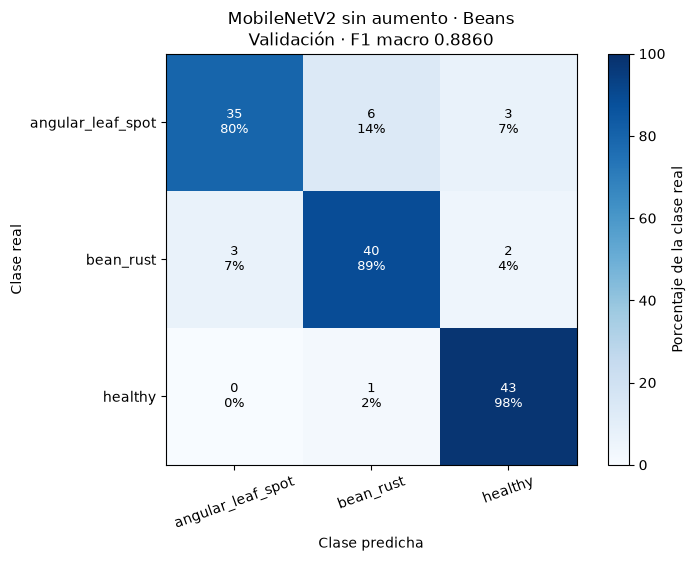

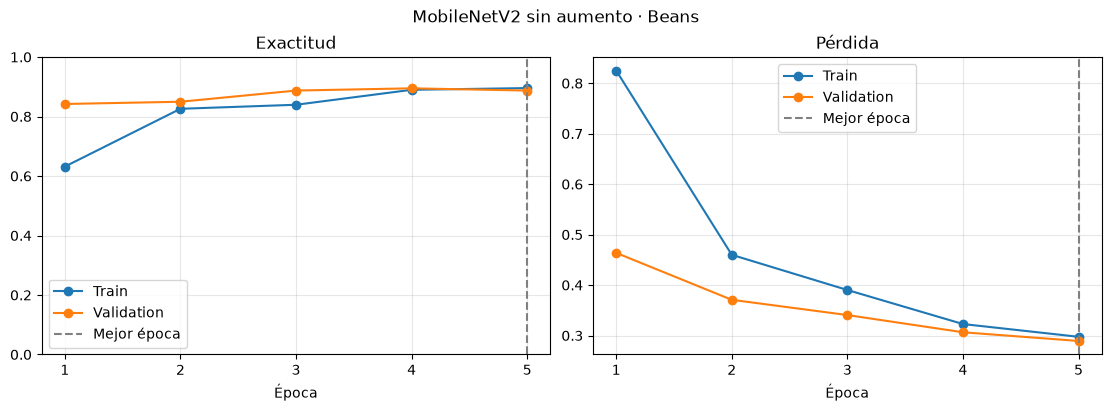

In [11]:
# EVALUAR CORRIDA 1 (no vuelve a entrenar)
resumen_1 = evaluar(carpeta_base, "MobileNetV2 sin aumento · Beans")

In [12]:
print("Train con aumento:",
      train_con_aumento.cardinality().numpy(),
      "lotes")

Train con aumento: 33 lotes


### Corrida 2: base congelada con aumento horizontal

Corrida 2 · MobileNetV2 con aumento horizontal
Se crea un modelo nuevo desde los mismos pesos preentrenados de ImageNet, pero durante Train se usa el volteo horizontal aleatorio (train_con_aumento).

In [13]:
# CORRIDA 2 · Base congelada con aumento horizontal · 5 épocas
modelo, base = construir_mobilenetv2(len(clases), "beans")
compilar(modelo, 1e-3)
carpeta_aumento = entrenar(modelo, "base_con_aumento", epocas=5, datos_train=train_con_aumento)

Resultados de esta corrida en: C:\Users\Laddy\entrenamiento\BeanCass-AI\beans\resultados\mobilenetv2\base_con_aumento_20261121_174335_517871
Parámetros totales: 2,261,827 · entrenables: 3,843
Epoch 1/5
33/33 - 26s - 776ms/step - accuracy: 0.6412 - loss: 0.7646 - val_accuracy: 0.8496 - val_loss: 0.4473
Epoch 2/5
33/33 - 19s - 591ms/step - accuracy: 0.8250 - loss: 0.4598 - val_accuracy: 0.8797 - val_loss: 0.3551
Epoch 3/5
33/33 - 19s - 578ms/step - accuracy: 0.8801 - loss: 0.3566 - val_accuracy: 0.8872 - val_loss: 0.3330
Epoch 4/5
33/33 - 19s - 589ms/step - accuracy: 0.8801 - loss: 0.3185 - val_accuracy: 0.9023 - val_loss: 0.2888
Epoch 5/5
33/33 - 19s - 569ms/step - accuracy: 0.9043 - loss: 0.2775 - val_accuracy: 0.9248 - val_loss: 0.2747
Entrenamiento realizado en 102.44 segundos
Mejor modelo guardado: True


Orden de clases: ['angular_leaf_spot', 'bean_rust', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[41  3  0]
 [ 4 39  2]
 [ 0  1 43]]

Clase              Aciertos   Precisión   Recall      F1
angular_leaf_spot    41/44       91.11%    93.18%   0.9213
bean_rust            39/45       90.70%    86.67%   0.8864
healthy              43/44       95.56%    97.73%   0.9663

Exactitud en Validation: 92.48%
F1 macro: 0.9247


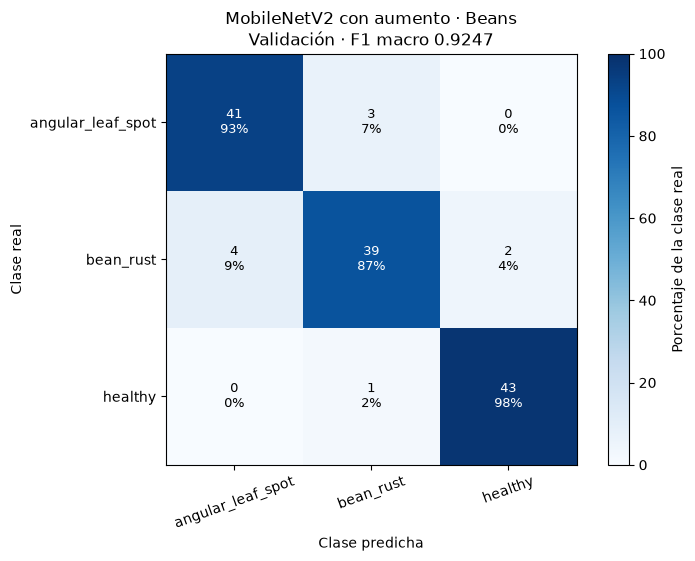

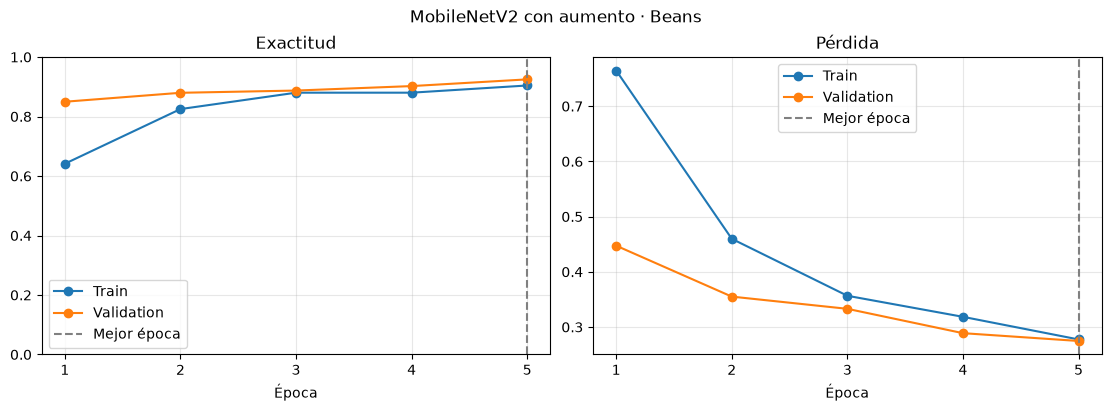

In [14]:
# EVALUAR CORRIDA 2 (no vuelve a entrenar)
resumen_2 = evaluar(carpeta_aumento, "MobileNetV2 con aumento · Beans")

In [15]:
print("F1 Corrida 1:", resumen_1["f1_macro_validation"])
print("F1 Corrida 2:", resumen_2["f1_macro_validation"])
print("Modelo con aumento:", (carpeta_aumento / "mejor_modelo.keras").exists())

F1 Corrida 1: 0.886
F1 Corrida 2: 0.9247
Modelo con aumento: True


### Corrida 3: fine-tuning

Corrida 3 · Fine-tuning desde la mejor corrida anterior
Se elige el mejor F1 macro en Validation entre las dos bases congeladas, se carga su archivo .keras y se descongela parte final de MobileNetV2, manteniendo BatchNormalization congelada. Se utiliza una tasa menor (1e-4) para reducir cambios bruscos. .

In [16]:

# CORRIDA 3 · Fine-tuning · hasta 8 épocas

opciones = [
    (resumen_1, carpeta_base),
    (resumen_2, carpeta_aumento)
]

mejor_congelada = max(
    opciones,
    key=lambda par: par[0]["f1_macro_validation"]
)

print("Se parte de:", mejor_congelada[1].name)

carpeta_ajuste = ajuste_fino(
    mejor_congelada[1],
    "ajuste_fino",
    epocas=8,
    datos_train=train_con_aumento
)


Se parte de: base_con_aumento_20261121_174335_517871
Capas de la base entrenables en fine-tuning: 31 de 155
Resultados de esta corrida en: C:\Users\Laddy\entrenamiento\BeanCass-AI\beans\resultados\mobilenetv2\ajuste_fino_20261121_181000_639966
Parámetros totales: 2,261,827 · entrenables: 1,727,683
Epoch 1/8
33/33 - 34s - 1s/step - accuracy: 0.8114 - loss: 0.5276 - val_accuracy: 0.9323 - val_loss: 0.2317
Epoch 2/8
33/33 - 24s - 715ms/step - accuracy: 0.9226 - loss: 0.1777 - val_accuracy: 0.9474 - val_loss: 0.1891
Epoch 3/8
33/33 - 23s - 701ms/step - accuracy: 0.9681 - loss: 0.0791 - val_accuracy: 0.9248 - val_loss: 0.1614
Epoch 4/8
33/33 - 23s - 699ms/step - accuracy: 0.9681 - loss: 0.0900 - val_accuracy: 0.9248 - val_loss: 0.1608
Epoch 5/8
33/33 - 22s - 676ms/step - accuracy: 0.9758 - loss: 0.0617 - val_accuracy: 0.9248 - val_loss: 0.2860
Epoch 6/8
33/33 - 23s - 689ms/step - accuracy: 0.9923 - loss: 0.0235 - val_accuracy: 0.9474 - val_loss: 0.1576
Epoch 7/8
33/33 - 23s - 683ms/step - a

Orden de clases: ['angular_leaf_spot', 'bean_rust', 'healthy']
Matriz de confusión (filas reales, columnas predichas):
[[39  5  0]
 [ 1 43  1]
 [ 0  0 44]]

Clase              Aciertos   Precisión   Recall      F1
angular_leaf_spot    39/44       97.50%    88.64%   0.9286
bean_rust            43/45       89.58%    95.56%   0.9247
healthy              44/44       97.78%   100.00%   0.9888

Exactitud en Validation: 94.74%
F1 macro: 0.9474


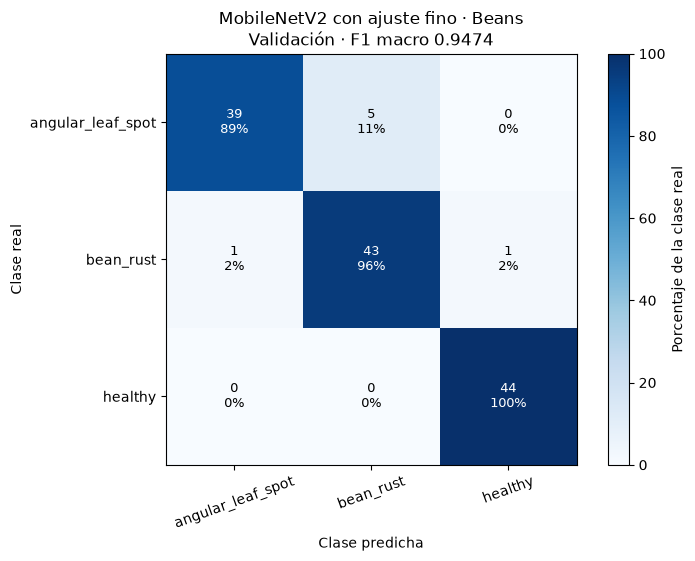

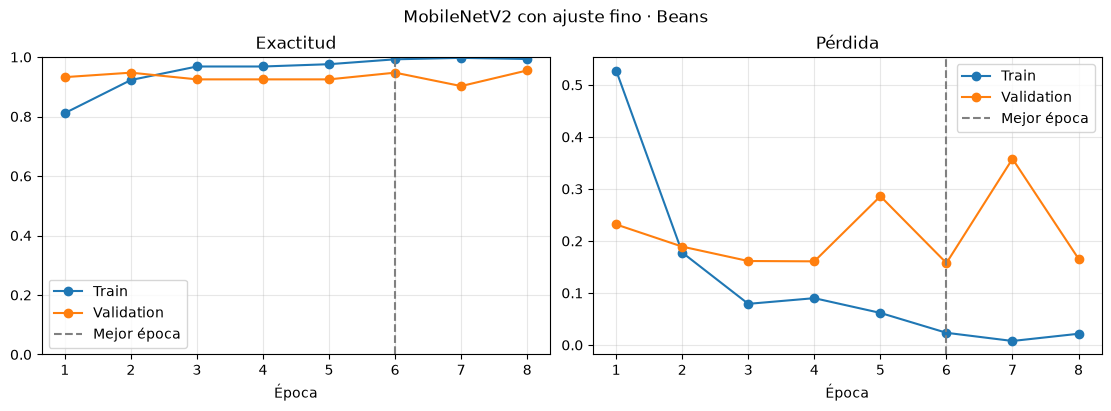

In [17]:
resumen_3 = evaluar(
    carpeta_ajuste,
    "MobileNetV2 con ajuste fino · Beans"
)

Comparación de las corridas en Validation
Elige la mejor configuración por F1 macro, sin utilizar Test. Todas las corridas se guardan en beans/resultados/mobilenetv2/.

In [18]:
# RESUMEN DE LAS TRES CORRIDAS
resumenes = [resumen_1, resumen_2, resumen_3]
carpetas = [carpeta_base, carpeta_aumento, carpeta_ajuste]

print(f"{'Corrida':<42} {'Accuracy':>10} {'F1 macro':>10}  "
      + "  ".join(f"{c:>18}" for c in clases))

for r in resumenes:
    print(
        f"{r['corrida']:<42} "
        f"{r['exactitud_validation']:>10.2%} "
        f"{r['f1_macro_validation']:>10.4f}  "
        + "  ".join(
            f"{r['f1_por_clase'][c]:>18.4f}"
            for c in clases
        )
    )

mejor_indice = max(
    range(len(resumenes)),
    key=lambda i: resumenes[i]["f1_macro_validation"]
)

mejor_resumen = resumenes[mejor_indice]
mejor_carpeta = carpetas[mejor_indice]

print("\nMejor corrida de MobileNetV2 en Beans:",
      mejor_carpeta.name)

(carpeta_resultados / "comparacion_corridas.json").write_text(
    json.dumps(
        {"mejor": mejor_carpeta.name, "corridas": resumenes},
        indent=2,
        ensure_ascii=False
    ),
    encoding="utf-8"
)


Corrida                                      Accuracy   F1 macro   angular_leaf_spot           bean_rust             healthy
base_sin_aumento_20261121_165924_750727        88.72%     0.8860              0.8537              0.8696              0.9348
base_con_aumento_20261121_174335_517871        92.48%     0.9247              0.9213              0.8864              0.9663
ajuste_fino_20261121_181000_639966             94.74%     0.9474              0.9286              0.9247              0.9888

Mejor corrida de MobileNetV2 en Beans: ajuste_fino_20261121_181000_639966


4331

In [19]:
print("Mejor modelo:", mejor_carpeta.name)

print(
    "Modelo guardado:",
    (mejor_carpeta / "mejor_modelo.keras").exists()
)

print("Lotes de Test:", test_preparado.cardinality().numpy())

Mejor modelo: ajuste_fino_20261121_181000_639966
Modelo guardado: True
Lotes de Test: 4


### Evaluación final del mejor modelo con Test 

In [20]:
# Evaluación final; DESACTIVADA por defecto.
EJECUTAR_TEST_FINAL = True

if EJECUTAR_TEST_FINAL:
    modelo_test = keras.models.load_model(str(mejor_carpeta / "mejor_modelo.keras"), compile=False)
    matriz = np.zeros((len(clases), len(clases)), dtype=int)
    for imagenes, etiquetas in test_preparado:
        predichas = np.argmax(modelo_test(imagenes, training=False).numpy(), axis=1)
        np.add.at(matriz, (etiquetas.numpy(), predichas), 1)
    aciertos = np.diag(matriz)
    total_real = matriz.sum(axis=1)
    total_pred = matriz.sum(axis=0)
    f1 = 2 * aciertos / np.maximum(total_real + total_pred, 1)
    recall = aciertos / np.maximum(total_real, 1)
    accuracy = float(aciertos.sum() / matriz.sum())
    print("Modelo evaluado:", mejor_carpeta.name)
    print("Matriz de confusión Test:\n", matriz)
    print("Accuracy Test:", f"{accuracy:.2%}", "| F1 macro Test:", f"{f1.mean():.4f}")
    for clase, rc, f in zip(clases, recall, f1):
        print(clase, "Recall:", f"{rc:.2%}", "F1:", f"{f:.4f}")
    (mejor_carpeta / "metricas_test.json").write_text(
        json.dumps({"modelo": mejor_carpeta.name, "accuracy_test": accuracy,
                    "f1_macro_test": float(f1.mean()), "matriz_confusion": matriz.tolist(),
                    "recall_por_clase": {c: float(v) for c,v in zip(clases,recall)},
                    "f1_por_clase": {c: float(v) for c,v in zip(clases,f1)}},
                   indent=2, ensure_ascii=False), encoding="utf-8")
else:
    print("Test reservado. No se ha evaluado todavía.")

Modelo evaluado: ajuste_fino_20261121_181000_639966
Matriz de confusión Test:
 [[42  1  0]
 [ 3 40  0]
 [ 0  0 42]]
Accuracy Test: 96.88% | F1 macro Test: 0.9690
angular_leaf_spot Recall: 97.67% F1: 0.9545
bean_rust Recall: 93.02% F1: 0.9524
healthy Recall: 100.00% F1: 1.0000
